# Yağmur Yağdı, Barajlar Neden Dolmadı? İstanbul’un Suyunu Veriyle Okumak

Medium makalesindeki tüm grafik ve rakamları üreten notebook.

**Veri:** İBB Açık Veri Portalı (İSKİ verileri), ham dosyalar [Uguravsar75/istanbul-baraj-analizi](https://github.com/Uguravsar75/istanbul-baraj-analizi) reposunun `data/raw/` klasöründen okunur:
- İstanbul barajları günlük genel doluluk oranı ve rezerv su (2005-01-01 – 2021-04-07)
- 10 baraj havzasına düşen günlük yağış ve İstanbul günlük su tüketimi (2011-01-01 – 2024-02-18)

**Makale:** Medium linki README’de.

## Kurulum

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BASE = Path(".")
OUT = BASE / "gorseller"
OUT.mkdir(exist_ok=True)
REPO = "https://raw.githubusercontent.com/Uguravsar75/istanbul-baraj-analizi/main/data/raw/"
LOCAL = BASE / "veri"
DOLULUK = "dam_occupancy.csv"
YAGIS = "istanbul-barajlarnda-ya-ve-gunluk-tuketim-verileri.xlsx"


def yol(ad):
    p = LOCAL / ad
    return p if p.exists() else REPO + ad


# ---------- Görsel stil (seride ortak) ----------
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
LIGHT = "#c9c6bd"
AYLAR = ["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]
AY_UZUN = ["Ocak", "Şubat", "Mart", "Nisan", "Mayıs", "Haziran", "Temmuz", "Ağustos",
           "Eylül", "Ekim", "Kasım", "Aralık"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
})
YUZDE = FuncFormatter(lambda v, _: f"%{v:g}".replace(".", ","))


def save(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight", pad_inches=0.35)
    plt.show()


def tr(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def binlik(n):
    return f"{n:,.0f}".replace(",", ".")


## 0. Veriyi oku ve kontrol et
Tekrar eden tarihler, aykırı değer (19 Nisan 2020, %80,79), eksik günler ve havza adları. Ham dosyalar değiştirilmez.

In [2]:
ham = pd.read_csv(yol(DOLULUK))
tekrar = ham[ham["DATE"].duplicated(keep=False)]
print(f"Doluluk ham: {len(ham)} satır, tekrar eden tarih: {tekrar['DATE'].nunique()} "
      f"({', '.join(sorted(tekrar['DATE'].unique()))})")
print(tekrar.to_string(index=False))

# 2020-04-19'daki %80,79 değeri bir gün önce ve sonraki %70'lerle tutarsız (aykırı); 2021-01-07 birebir tekrar.
dol = ham[~((ham["DATE"] == "2020-04-19") & (ham["GENERAL_DAM_OCCUPANCY_RATE"] == 80.79))]
dol = dol.drop_duplicates("DATE").assign(DATE=lambda t: pd.to_datetime(t["DATE"])).set_index("DATE").sort_index()
tum_gunler = pd.date_range(dol.index.min(), dol.index.max(), freq="D")
eksik = tum_gunler.difference(dol.index)
print(f"Eksik gün: {len(eksik)} ({', '.join(d.strftime('%Y-%m-%d') for d in eksik)}) -> doğrusal ara değer")
dol = dol.reindex(tum_gunler).interpolate()
oc = dol["GENERAL_DAM_OCCUPANCY_RATE"]
rez = dol["GENERAL_DAM_RESERVED_WATER"]
print(f"Temiz doluluk serisi: {len(oc)} gün, {oc.index.min().date()} – {oc.index.max().date()}")
print(f"Toplam kapasite (zirve günü rezerv / doluluk): ~{rez[oc.idxmax()] / oc.max() * 100:.0f} milyon m³")

x = pd.read_excel(yol(YAGIS))
x = x.drop(columns=[c for c in x.columns if str(c).startswith("Unnamed")])
x["Tarih"] = pd.to_datetime(x["Tarih"])
x = x.set_index("Tarih").sort_index()
TUK = "İstanbul günlük tüketim(m³/gün)"
HAVZA = [c for c in x.columns if c != TUK]
assert len(HAVZA) == 10
print(f"Yağış/tüketim: {len(x)} gün, {x.index.min().date()} – {x.index.max().date()}, "
      f"boş değer {int(x.isna().sum().sum())}, negatif {int((x < 0).sum().sum())}")
yagis = x[HAVZA].mean(axis=1)          # 10 havzanın basit ortalaması (mm/gün)
tuk = x[TUK] / 1e6                     # milyon m³/gün


Doluluk ham: 5941 satır, tekrar eden tarih: 2 (2020-04-19, 2021-01-07)
      DATE  GENERAL_DAM_OCCUPANCY_RATE  GENERAL_DAM_RESERVED_WATER
2020-04-19                       80.79                         701
2020-04-19                       70.03                         608
2021-01-07                       19.35                         168
2021-01-07                       19.35                         168
Eksik gün: 2 (2020-06-05, 2020-07-31) -> doğrusal ara değer
Temiz doluluk serisi: 5941 gün, 2005-01-01 – 2021-04-07
Toplam kapasite (zirve günü rezerv / doluluk): ~868 milyon m³


Yağış/tüketim: 4797 gün, 2011-01-01 – 2024-02-18, boş değer 0, negatif 0


## 1. Doluluk 2005–2021 ve %30’un altındaki dönemler
%30, projede kurak dönemleri işaretlemek için seçilen bir eşiktir; resmî bir tanım değildir.


Doluluk ortalaması: %64,76 | en yüksek %99,16 (2010-03-22) | en düşük %9,20 (2007-11-05, 80 milyon m³)
%30 altındaki gün sayısı (yıl): {2007: 159, 2008: 210, 2014: 192, 2020: 60, 2021: 17} toplam 638
  2008 en düşük: %15,72 (2008-09-25)
  2014 en düşük: %14,46 (2014-09-16)
  2020 en düşük: %20,29 (2020-12-31)
  2021 en düşük: %19,16 (2021-01-09)


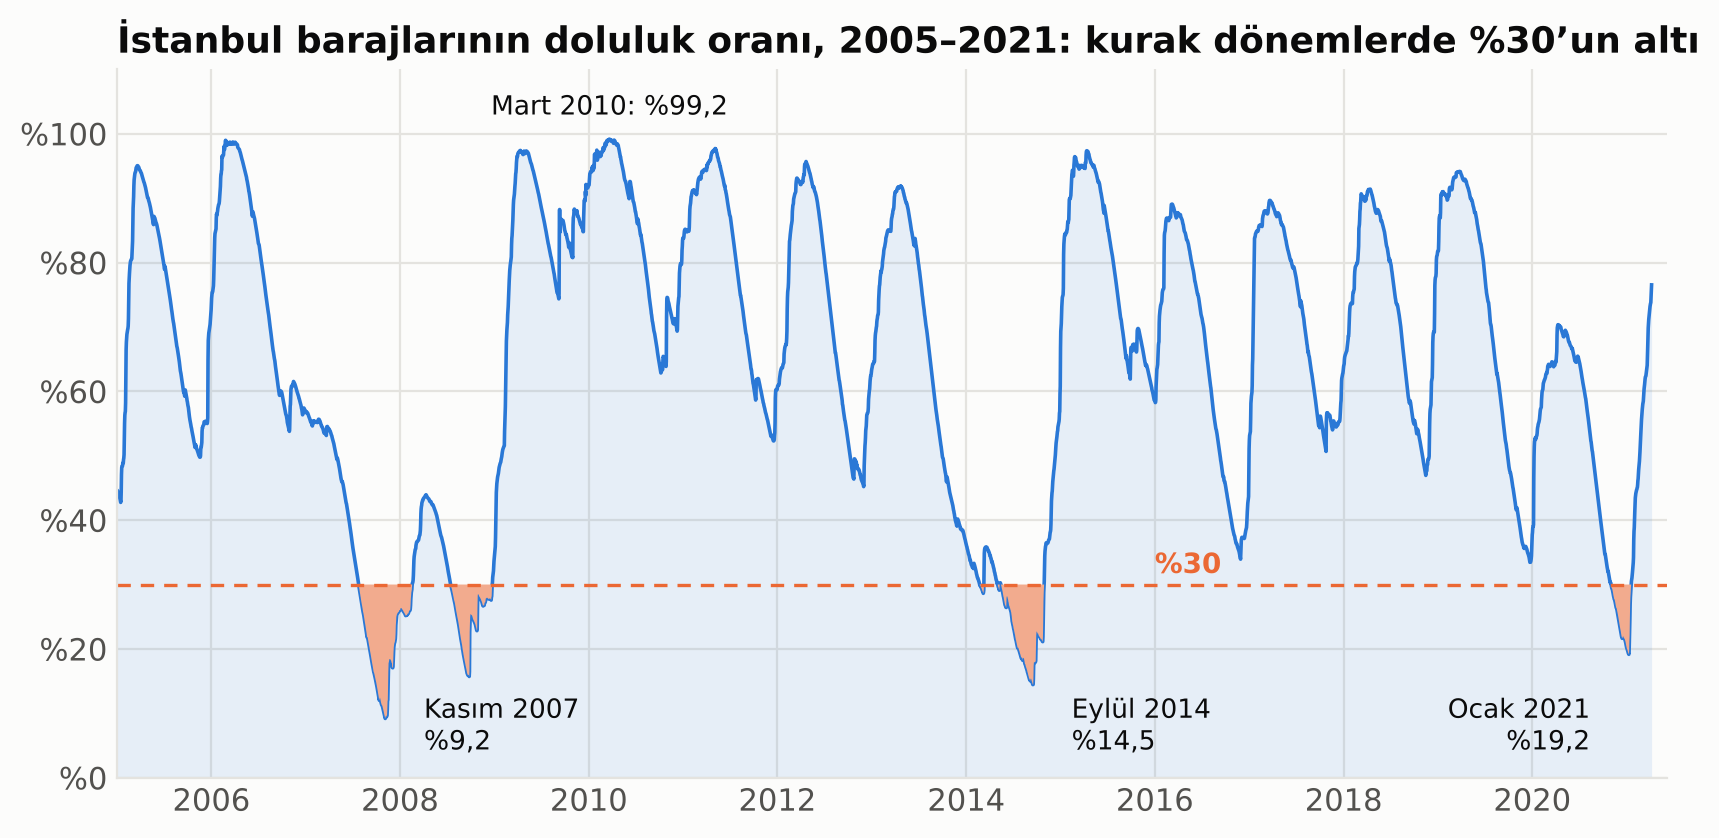

In [3]:
print(f"\nDoluluk ortalaması: %{tr(oc.mean(), 2)} | en yüksek %{tr(oc.max(), 2)} ({oc.idxmax().date()}) | "
      f"en düşük %{tr(oc.min(), 2)} ({oc.idxmin().date()}, {rez.min():.0f} milyon m³)")
alt30 = oc < 30
yil_alt30 = alt30.groupby(oc.index.year).sum()
print("%30 altındaki gün sayısı (yıl):", {int(k): int(v) for k, v in yil_alt30[yil_alt30 > 0].items()},
      f"toplam {int(alt30.sum())}")
for y in [2008, 2014, 2020, 2021]:
    s = oc[str(y)]
    print(f"  {y} en düşük: %{tr(s.min(), 2)} ({s.idxmin().date()})")

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(oc.index, oc.values, color=BLUE, alpha=0.10, lw=0)
ax.plot(oc.index, oc.values, color=BLUE, lw=1.3)
ax.set_axisbelow(True)
ax.fill_between(oc.index, oc.values, 30, where=alt30.values, color="#f2ab8e", lw=0, interpolate=True, zorder=2)
ax.axhline(30, color=ORANGE, lw=1.2, ls=(0, (4, 3)))
ax.text(pd.Timestamp("2016-01-01"), 31.8, "%30", color=ORANGE, fontsize=10, fontweight="bold")
for t, lab, dx in [("2007-11-05", "Kasım 2007\n%9,2", 150), ("2014-09-16", "Eylül 2014\n%14,5", 150),
                   ("2021-01-09", "Ocak 2021\n%19,2", -150)]:
    ax.text(pd.Timestamp(t) + pd.Timedelta(days=dx), 3, lab, color=INK, fontsize=9.5,
            ha="left" if dx > 0 else "right", va="bottom")
ax.text(oc.idxmax(), 102, "Mart 2010: %99,2", color=INK, fontsize=9.5, ha="center", va="bottom")
ax.set_ylim(0, 110); ax.set_yticks(range(0, 101, 20)); ax.yaxis.set_major_formatter(YUZDE)
ax.set_xlim(oc.index.min(), oc.index.max() + pd.Timedelta(days=60))
ax.set_title("İstanbul barajlarının doluluk oranı, 2005–2021: kurak dönemlerde %30’un altı", fontsize=13)
save(fig, "01_doluluk_2005_2021.png")


## 2. Bir yılın döngüsü (2011–2020 ortalaması)
Yağış, doluluk ve tüketimin aylık ortalamaları.


[Grafik 2] 2011–2020 aylık ortalamalar
  yağış (mm/ay): {'Oca': 97, 'Şub': 77, 'Mar': 61, 'Nis': 50, 'May': 45, 'Haz': 47, 'Tem': 21, 'Ağu': 26, 'Eyl': 69, 'Eki': 96, 'Kas': 76, 'Ara': 102}
  doluluk (%):   {'Oca': 67.8, 'Şub': 77.4, 'Mar': 82.4, 'Nis': 83.7, 'May': 81.1, 'Haz': 76.1, 'Tem': 68.8, 'Ağu': 60.0, 'Eyl': 51.8, 'Eki': 47.5, 'Kas': 45.6, 'Ara': 48.7}
  tüketim (mn m³/gün): {'Oca': 2.48, 'Şub': 2.47, 'Mar': 2.49, 'Nis': 2.54, 'May': 2.68, 'Haz': 2.81, 'Tem': 2.87, 'Ağu': 2.84, 'Eyl': 2.8, 'Eki': 2.66, 'Kas': 2.62, 'Ara': 2.57}
  Kasım–Mart yağışın yıllık toplamdaki payı: %53,9 | yıllık ortalama 766 mm
  doluluk zirve Nisan %83,7, dip Kasım %45,6 | tüketim zirve Temmuz 2,87, en düşük Şubat 2,47 (fark %15,9)


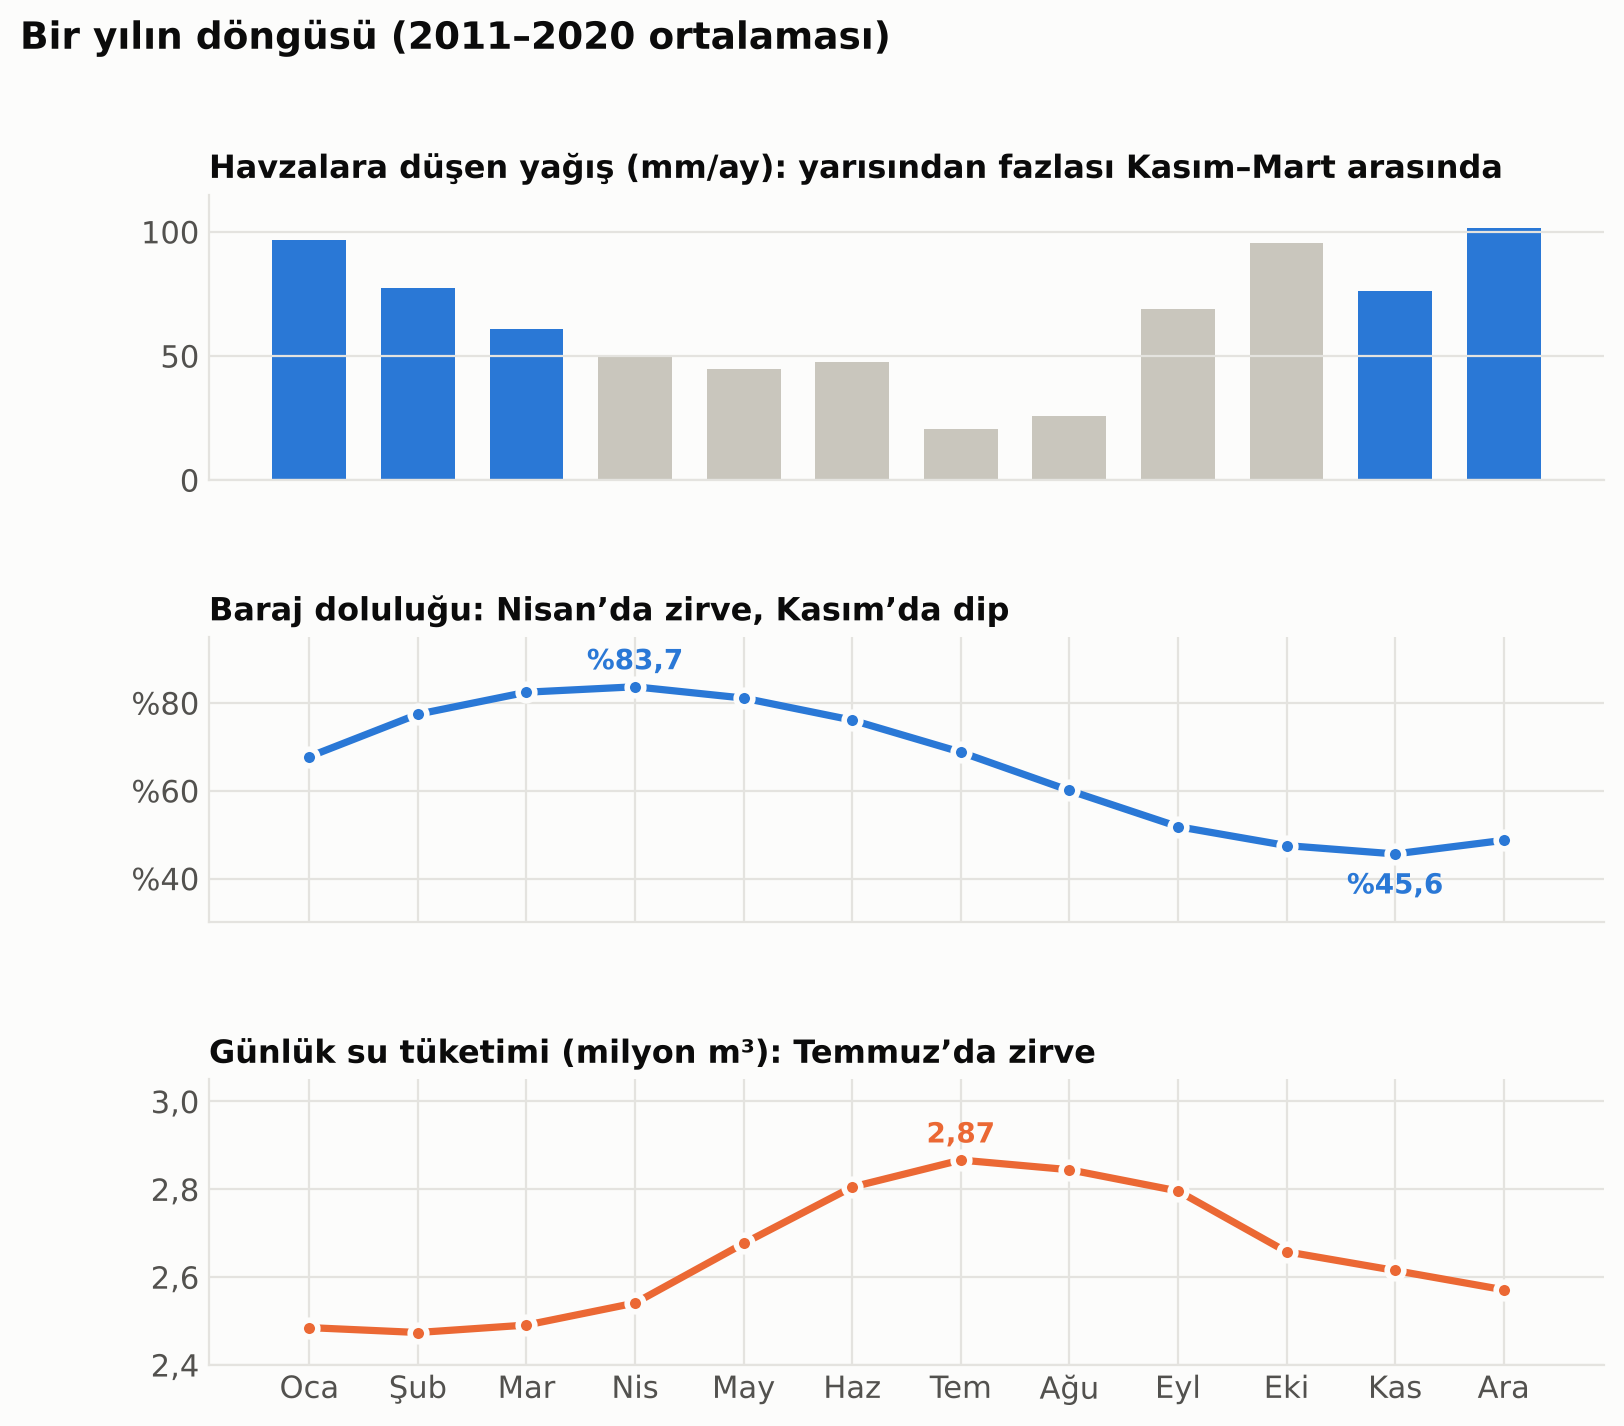

In [4]:
DONEM = slice("2011-01-01", "2020-12-31")   # iki veri setinin tam yıl olarak örtüştüğü dönem
ay_yagis = yagis[DONEM].resample("MS").sum()
ay_yagis = ay_yagis.groupby(ay_yagis.index.month).mean()
ay_dol = oc[DONEM].groupby(oc[DONEM].index.month).mean()
ay_tuk = tuk[DONEM].groupby(tuk[DONEM].index.month).mean()
print(f"\n[Grafik 2] 2011–2020 aylık ortalamalar")
print("  yağış (mm/ay):", {AYLAR[k - 1]: round(v) for k, v in ay_yagis.items()})
print("  doluluk (%):  ", {AYLAR[k - 1]: round(v, 1) for k, v in ay_dol.items()})
print("  tüketim (mn m³/gün):", {AYLAR[k - 1]: round(v, 2) for k, v in ay_tuk.items()})
kis = ay_yagis.loc[[11, 12, 1, 2, 3]].sum() / ay_yagis.sum() * 100
print(f"  Kasım–Mart yağışın yıllık toplamdaki payı: %{tr(kis)} | yıllık ortalama {ay_yagis.sum():.0f} mm")
print(f"  doluluk zirve {AY_UZUN[ay_dol.idxmax() - 1]} %{tr(ay_dol.max())}, dip {AY_UZUN[ay_dol.idxmin() - 1]} %{tr(ay_dol.min())}"
      f" | tüketim zirve {AY_UZUN[ay_tuk.idxmax() - 1]} {tr(ay_tuk.max(), 2)}, en düşük {AY_UZUN[ay_tuk.idxmin() - 1]} {tr(ay_tuk.min(), 2)}"
      f" (fark %{tr((ay_tuk.max() / ay_tuk.min() - 1) * 100)})")

m = np.arange(12)
fig, axes = plt.subplots(3, 1, figsize=(9, 7.6), sharex=True, gridspec_kw=dict(hspace=0.55))
a0, a1, a2 = axes
renk = [BLUE if k in (11, 12, 1, 2, 3) else LIGHT for k in range(1, 13)]
a0.bar(m, ay_yagis.values, color=renk, width=0.68)
a0.set_title("Havzalara düşen yağış (mm/ay): yarısından fazlası Kasım–Mart arasında", fontsize=11.5)
a0.set_ylim(0, 115); a0.grid(axis="x", visible=False)
a1.plot(m, ay_dol.values, color=BLUE, lw=2.6, marker="o", ms=6, mec=SURFACE, mew=2)
a1.set_title("Baraj doluluğu: Nisan’da zirve, Kasım’da dip", fontsize=11.5)
a1.set_ylim(30, 95); a1.yaxis.set_major_formatter(YUZDE)
i = ay_dol.idxmax() - 1; a1.text(i, ay_dol.max() + 4, f"%{tr(ay_dol.max())}", ha="center", color=BLUE, fontweight="bold", fontsize=10)
i = ay_dol.idxmin() - 1; a1.text(i, ay_dol.min() - 9, f"%{tr(ay_dol.min())}", ha="center", color=BLUE, fontweight="bold", fontsize=10)
a2.plot(m, ay_tuk.values, color=ORANGE, lw=2.6, marker="o", ms=6, mec=SURFACE, mew=2)
a2.set_title("Günlük su tüketimi (milyon m³): Temmuz’da zirve", fontsize=11.5)
a2.set_ylim(2.4, 3.05)
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: tr(v, 1)))
i = ay_tuk.idxmax() - 1; a2.text(i, ay_tuk.max() + 0.04, tr(ay_tuk.max(), 2), ha="center", color=ORANGE, fontweight="bold", fontsize=10)
a2.set_xticks(m); a2.set_xticklabels(AYLAR)
fig.suptitle("Bir yılın döngüsü (2011–2020 ortalaması)", x=0.02, ha="left", fontsize=13.5, fontweight="bold", color=INK, y=0.995)
save(fig, "02_yillik_dongu.png")


## 3. Kış yağışı ve bahar zirvesi (2012–2020 su yılları)
Su yılı = Ekim–Eylül, kış = Kasım–Mart, bahar zirvesi = Mart–Mayıs en yüksek doluluk. Not: Korelasyon (0,62) büyük ölçüde 2014’ten gelir; 2014 hariç −0,04 (n = 9).


[Grafik 3] su yılı (Ekim–Eylül) tablosu
        kis  su_yili    yaz  baslangic  zirve  kazanc
yil                                                  
2012  379.0    785.5  406.5       52.3   95.7    43.4
2013  498.2    737.2  239.1       45.2   91.9    46.7
2014  287.3    871.4  584.1       36.4   35.8    -0.6
2015  441.4    926.8  485.5       21.1   97.4    76.2
2016  333.9    655.3  321.4       58.6   89.1    30.4
2017  499.2    865.0  365.8       33.9   89.6    55.7
2018  479.8    838.6  358.7       50.7   91.4    40.7
2019  456.8    629.9  173.1       46.9   94.1    47.2
2020  445.2    727.4  282.2       33.4   70.4    36.9
  korelasyon: kış yağışı ~ bahar zirvesi r=0.62 | kış yağışı ~ kazanç r=0.71 | su yılı toplam yağışı ~ bahar zirvesi r=-0.20 (n=9) | 2014 hariç kış ~ zirve r=-0.04
  2014 dışındaki yıllarda bahar zirvesi: %70,3 – %97,4 | 2014 dışında kış yağışı 334–499 mm
  2014 dibi: %14,46 (2014-09-16) | Eylül 2014 yağışı dipten önce 63 mm, sonra 148 mm | 30 Eylül doluluk %22,6

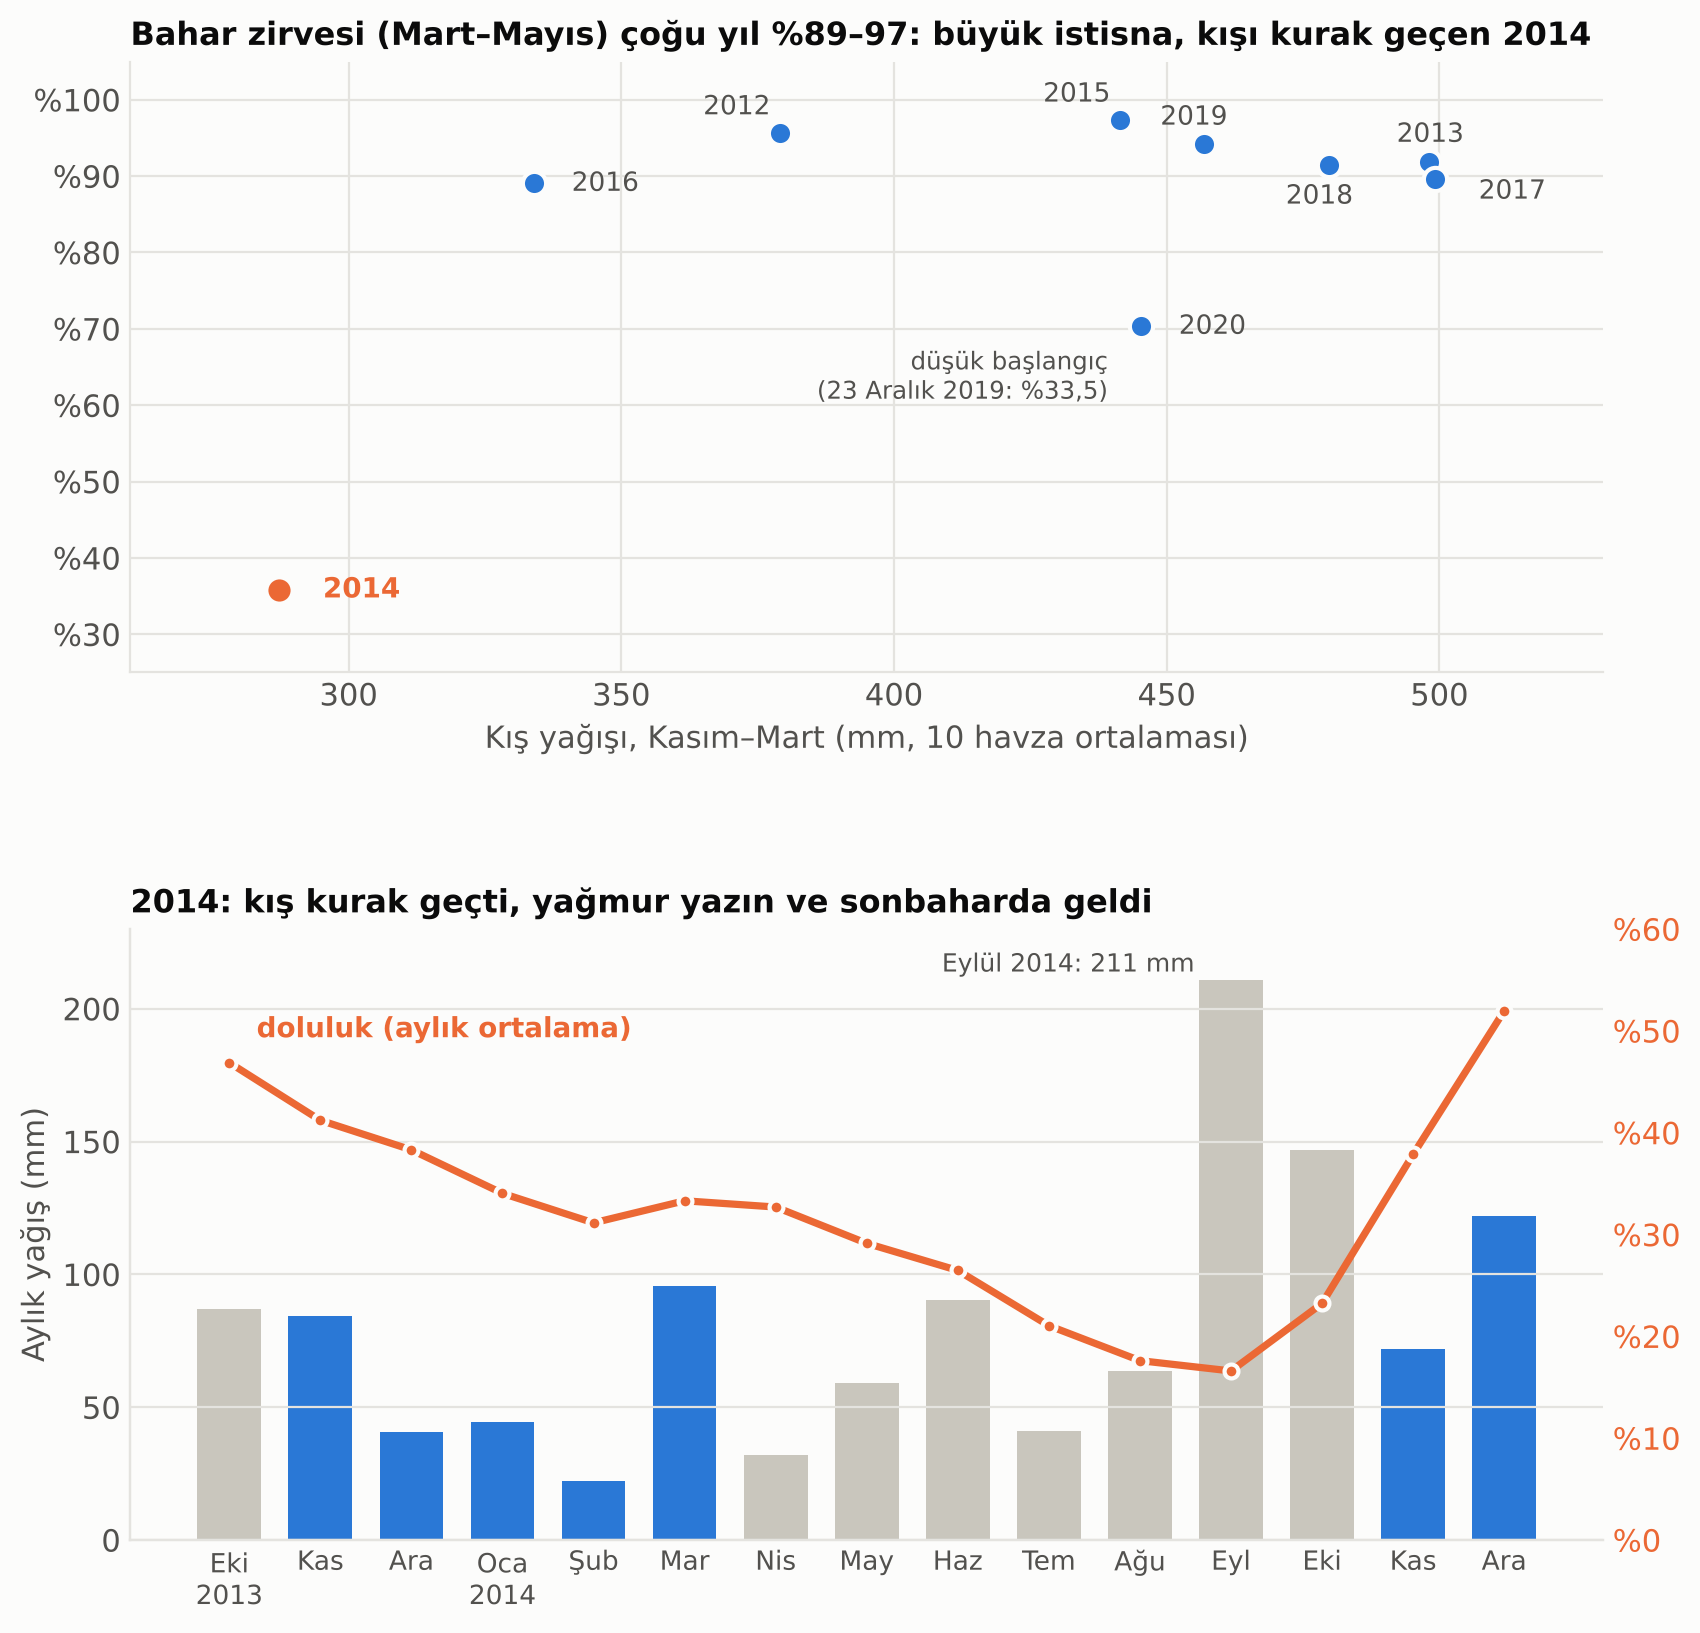

In [5]:
satir = []
for y in range(2012, 2021):
    kis_y = yagis[f"{y - 1}-11-01":f"{y}-03-31"].sum()
    su_yili = yagis[f"{y - 1}-10-01":f"{y}-09-30"].sum()
    zirve = oc[f"{y}-03-01":f"{y}-05-31"].max()        # bahar zirvesi: Mart–Mayıs
    baslangic = oc[f"{y - 1}-10-01":f"{y - 1}-12-31"].min()
    satir.append(dict(yil=y, kis=kis_y, su_yili=su_yili, yaz=su_yili - kis_y, baslangic=baslangic, zirve=zirve))
t = pd.DataFrame(satir).set_index("yil")
t["kazanc"] = t["zirve"] - t["baslangic"]
r_zirve = np.corrcoef(t["kis"], t["zirve"])[0, 1]
r_kazanc = np.corrcoef(t["kis"], t["kazanc"])[0, 1]
r_su = np.corrcoef(t["su_yili"], t["zirve"])[0, 1]
r_2014siz = np.corrcoef(t.drop(2014)["kis"], t.drop(2014)["zirve"])[0, 1]
print("\n[Grafik 3] su yılı (Ekim–Eylül) tablosu")
print(t.round(1).to_string())
print(f"  korelasyon: kış yağışı ~ bahar zirvesi r={r_zirve:.2f} | kış yağışı ~ kazanç r={r_kazanc:.2f} | "
      f"su yılı toplam yağışı ~ bahar zirvesi r={r_su:.2f} (n={len(t)}) | 2014 hariç kış ~ zirve r={r_2014siz:.2f}")
print(f"  2014 dışındaki yıllarda bahar zirvesi: %{tr(t.drop(2014)['zirve'].min())} – %{tr(t.drop(2014)['zirve'].max())}"
      f" | 2014 dışında kış yağışı {t.drop(2014)['kis'].min():.0f}–{t.drop(2014)['kis'].max():.0f} mm")
dip14 = oc["2014-09"].idxmin()
print(f"  2014 dibi: %{tr(oc[dip14], 2)} ({dip14.date()}) | Eylül 2014 yağışı dipten önce {yagis['2014-09-01':dip14].sum():.0f} mm, "
      f"sonra {yagis[dip14 + pd.Timedelta(days=1):'2014-09-30'].sum():.0f} mm | 30 Eylül doluluk %{tr(oc['2014-09-30'])}"
      f" | Ekim 2013 – dip arası yağış {yagis['2013-10-01':dip14].sum():.0f} mm")
print(f"  Ekim–Aralık 2019 en düşük: %{tr(oc['2019-10':'2019-12'].min())} ({oc['2019-10':'2019-12'].idxmin().date()})")
print(f"  2014: su yılı yağışı {t.loc[2014, 'su_yili']:.0f} mm (ortalama {t['su_yili'].mean():.0f}), "
      f"kış {t.loc[2014, 'kis']:.0f} mm (diğer yılların ortalaması {t.drop(2014)['kis'].mean():.0f}), "
      f"bahar zirvesi %{tr(t.loc[2014, 'zirve'])}")
ay14 = yagis["2013-10-01":"2014-12-31"].resample("MS").sum()
print("  2013-10 – 2014-12 aylık yağış:", {d.strftime('%Y-%m'): round(v) for d, v in ay14.items()})

fig, (ax, bx) = plt.subplots(2, 1, figsize=(9.5, 9.6), gridspec_kw=dict(hspace=0.42))
dig = t.drop(2014)
ax.scatter(dig["kis"], dig["zirve"], s=70, color=BLUE, edgecolor=SURFACE, lw=1.5, zorder=3)
ax.scatter(t.loc[2014, "kis"], t.loc[2014, "zirve"], s=90, color=ORANGE, edgecolor=SURFACE, lw=1.5, zorder=3)
ofs = {2012: (-14, 2.4), 2013: (-6, 2.6), 2015: (-14, 2.4), 2016: (7, -1), 2017: (8, -2.6), 2018: (-8, -5),
       2019: (-8, 2.6), 2020: (7, -1)}
for y, (dx, dy) in ofs.items():
    ax.text(t.loc[y, "kis"] + dx, t.loc[y, "zirve"] + dy, str(y), fontsize=9.5, color=INK_2)
ax.text(t.loc[2014, "kis"] + 8, t.loc[2014, "zirve"] - 1, "2014", fontsize=10, color=ORANGE, fontweight="bold")
ax.text(t.loc[2020, "kis"] - 6, t.loc[2020, "zirve"] - 9.5, "düşük başlangıç\n(23 Aralık 2019: %33,5)",
        fontsize=8.8, color=INK_2, ha="right")
ax.set_xlabel("Kış yağışı, Kasım–Mart (mm, 10 havza ortalaması)")
ax.set_ylim(25, 105); ax.set_xlim(260, 530); ax.yaxis.set_major_formatter(YUZDE)
ax.set_title("Bahar zirvesi (Mart–Mayıs) çoğu yıl %89–97: büyük istisna, kışı kurak geçen 2014", fontsize=11.5)

ay_dol14 = oc["2013-10-01":"2014-12-31"].resample("MS").mean()
xx = np.arange(len(ay14))
bx.bar(xx, ay14.values, color=[BLUE if d.month in (11, 12, 1, 2, 3) else LIGHT for d in ay14.index], width=0.7)
bx.set_ylim(0, 230); bx.grid(axis="x", visible=False)
bx.set_ylabel("Aylık yağış (mm)")
bx2 = bx.twinx()
bx2.plot(xx, ay_dol14.values, color=ORANGE, lw=2.6, marker="o", ms=5, mec=SURFACE, mew=1.5)
bx2.set_ylim(0, 60); bx2.yaxis.set_major_formatter(YUZDE); bx2.grid(False)
bx2.spines["right"].set_visible(False); bx2.tick_params(colors=ORANGE)
bx.set_xticks(xx); bx.set_xticklabels([AYLAR[d.month - 1] + ("\n" + str(d.year) if (d.month == 1 or (d.year == 2013 and d.month == 10)) else "") for d in ay14.index], fontsize=9.5)
bx.set_title("2014: kış kurak geçti, yağmur yazın ve sonbaharda geldi", fontsize=11.5)
bx2.text(0.3, ay_dol14.iloc[0] + 2.5, "doluluk (aylık ortalama)", color=ORANGE, fontsize=10, ha="left", fontweight="bold")
bx.text(10.6, 214, "Eylül 2014: 211 mm", color=INK_2, fontsize=9, ha="right")
save(fig, "03_kis_yagisi.png")


## 4. Yıllık ortalama günlük tüketim (2011–2023)
2024 yalnızca 18 Şubat’a kadar olduğu için dahil edilmez.


[Grafik 4] yıllık ortalama günlük tüketim (milyon m³): {2011: 2.258, 2012: 2.385, 2013: 2.492, 2014: 2.533, 2015: 2.644, 2016: 2.728, 2017: 2.796, 2018: 2.852, 2019: 2.907, 2020: 2.933, 2021: 2.942, 2022: 3.024, 2023: 3.06}
  2011 → 2023: 2,26 → 3,06 (%35,6 artış), bir önceki yıla göre düşen yıl: yok
  günlük en düşük 1.949.139 m³ (2015-03-31), en yüksek 3.568.056 m³ (2023-07-26)
  yıllık toplam 2023: 1117 milyon m³


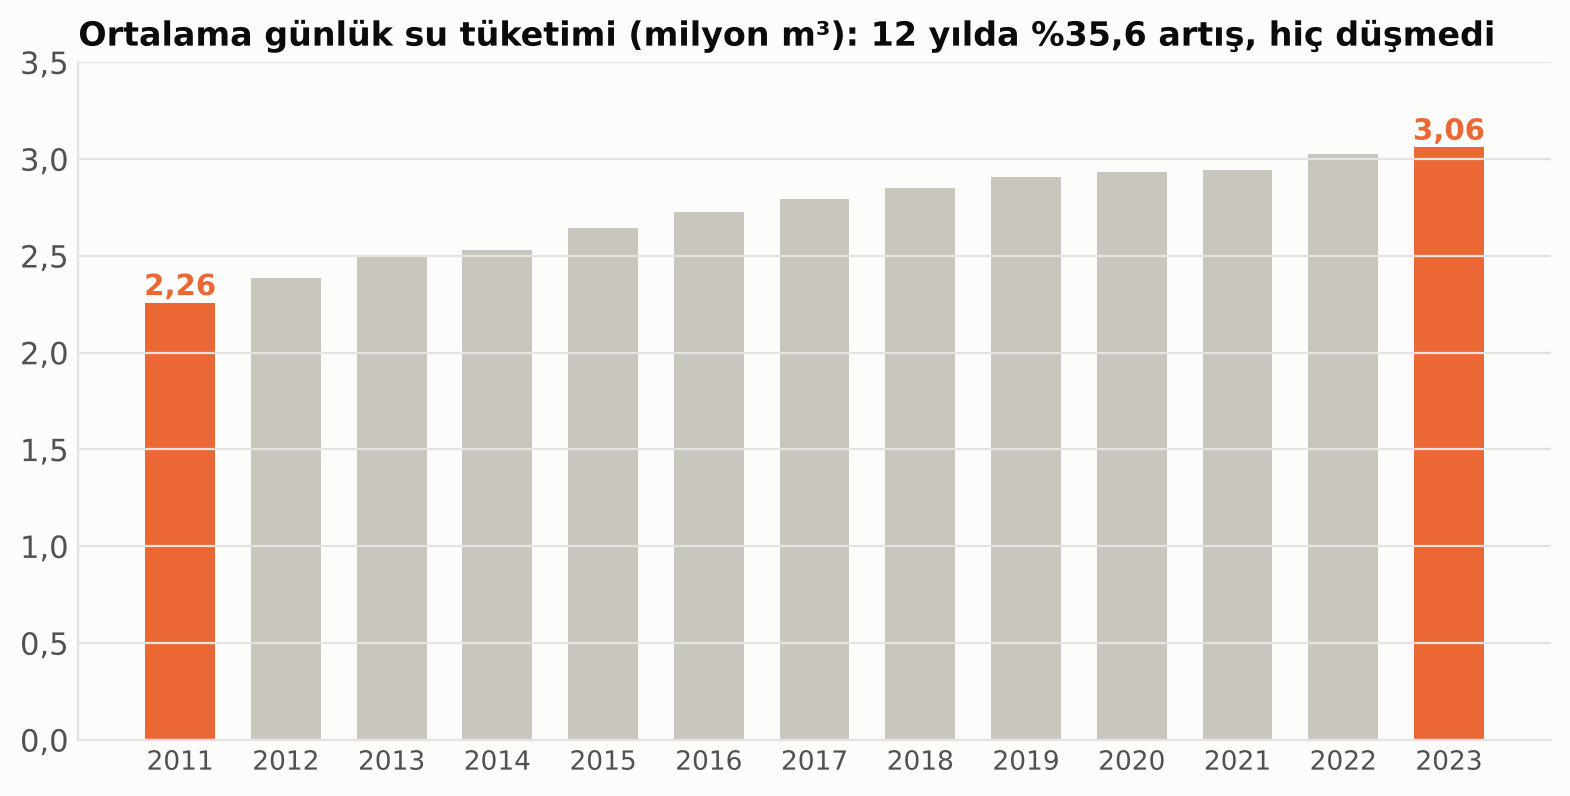


Görseller: gorseller


In [6]:
yt = tuk[:"2023"].groupby(tuk[:"2023"].index.year).mean()
artis = (yt[2023] / yt[2011] - 1) * 100
dusen = [int(y) for y in yt.index[1:] if yt[y] < yt[y - 1]]
print(f"\n[Grafik 4] yıllık ortalama günlük tüketim (milyon m³): {yt.round(3).to_dict()}")
print(f"  2011 → 2023: {tr(yt[2011], 2)} → {tr(yt[2023], 2)} (%{tr(artis)} artış), bir önceki yıla göre düşen yıl: {dusen or 'yok'}")
print(f"  günlük en düşük {binlik(x[TUK].min())} m³ ({x[TUK].idxmin().date()}), en yüksek {binlik(x[TUK].max())} m³ ({x[TUK].idxmax().date()})")
print(f"  yıllık toplam 2023: {tuk['2023'].sum():.0f} milyon m³")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
yy = yt.index.astype(int)
ax.bar(yy, yt.values, color=[ORANGE if y in (2011, 2023) else LIGHT for y in yy], width=0.66)
for y in (2011, 2023):
    ax.text(y, yt[y] + 0.04, tr(yt[y], 2), ha="center", color=ORANGE, fontweight="bold", fontsize=10.5)
ax.set_ylim(0, 3.5); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: tr(v, 1)))
ax.set_xticks(yy); ax.set_xticklabels([str(y) for y in yy], fontsize=9.5)
ax.set_title(f"Ortalama günlük su tüketimi (milyon m³): 12 yılda %{tr(artis)} artış, hiç düşmedi", fontsize=12)
save(fig, "04_tuketim.png")

print("\nGörseller:", OUT)
